# 📩 Spam SMS Detector: Naive Bayes

**Goal:** Classify a text message as **spam** or **ham** (a normal message).

**Problem type:** Binary text classification (0 = ham, 1 = spam)

**Dataset:** SMS Spam Collection, about 5,500 English text messages labelled as spam or ham

**Models compared:** Naive Bayes with different smoothing values, Naive Bayes with TF-IDF features, and Logistic Regression (for reference)

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn

**Workflow:** Load → Clean → EDA → Turn text into numbers → Train and compare models (with cross-validation) → Evaluate (precision, recall, confusion matrix) → Look at mistakes and the words that matter → Export the model for a website

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, classification_report)

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 1. Load the Data

The file is tab-separated and has no header row. Each line holds a label (`ham` or `spam`) followed by the message text.

In [2]:
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

try:
    df = pd.read_csv(URL, sep="\t", header=None, names=["label", "message"])
except Exception:
    # If the download fails, upload the file by hand
    print("Download failed. Please choose the file from your computer.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0], sep="\t", header=None, names=["label", "message"])

print("Shape:", df.shape)
print(df["label"].value_counts())
df.head(10)

Shape: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 2. Data Cleaning

Changes made:
- Remove rows with missing values
- Remove **duplicate messages**. This dataset repeats many messages, and if the same message appears in both the training and the test set, the test score looks better than it really is
- Create a numeric target (`ham` = 0, `spam` = 1) and the message length

In [3]:
before = len(df)
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before} | after: {len(df)} | removed: {before - len(df)}")

df["target"] = df["label"].map({"ham": 0, "spam": 1})
df["length"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()
df.head()

Rows before: 5572 | after: 5169 | removed: 403


,label,message,target,length,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20
1,ham,Ok lar... Joking wif u oni...,0,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28
3,ham,U dun say so early hor... U c already then say...,0,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13


## 3. Exploratory Data Analysis (EDA)

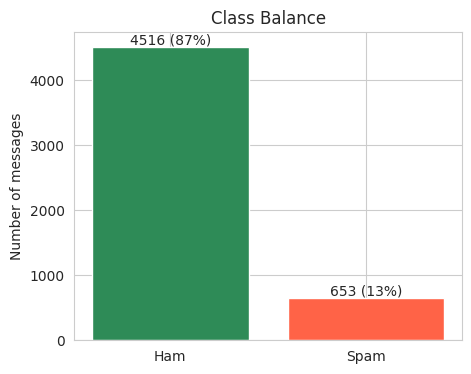

In [4]:
counts = df["label"].value_counts()

plt.figure(figsize=(5, 4))
plt.bar(["Ham", "Spam"], [counts["ham"], counts["spam"]], color=["seagreen", "tomato"])
for i, v in enumerate([counts["ham"], counts["spam"]]):
    plt.text(i, v + 40, f"{v} ({v / len(df) * 100:.0f}%)", ha="center")
plt.ylabel("Number of messages")
plt.title("Class Balance")
plt.show()

**Insight:** The data is **unbalanced**: spam is only a small share of all messages. A model that always says "ham" would already be right most of the time, so **accuracy alone is misleading** here. Precision and recall for the spam class matter more.

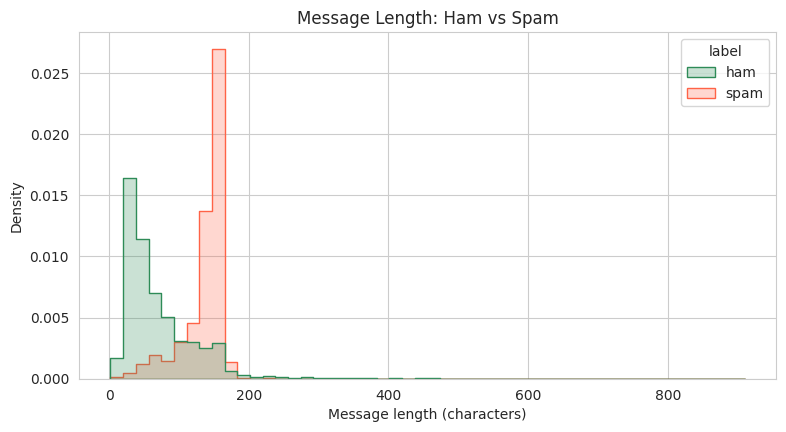

       length  word_count
label                    
ham      70.9        14.2
spam    137.7        23.7


In [5]:
plt.figure(figsize=(9, 4.5))
sns.histplot(data=df, x="length", hue="label", bins=50, palette={"ham": "seagreen", "spam": "tomato"},
             element="step", stat="density", common_norm=False)
plt.xlabel("Message length (characters)")
plt.title("Message Length: Ham vs Spam")
plt.show()

print(df.groupby("label")[["length", "word_count"]].mean().round(1))

**Insight:** Spam messages tend to be longer than normal messages, because they often include offers, prices, and instructions. Length is a useful hint, but the words themselves are the main signal.

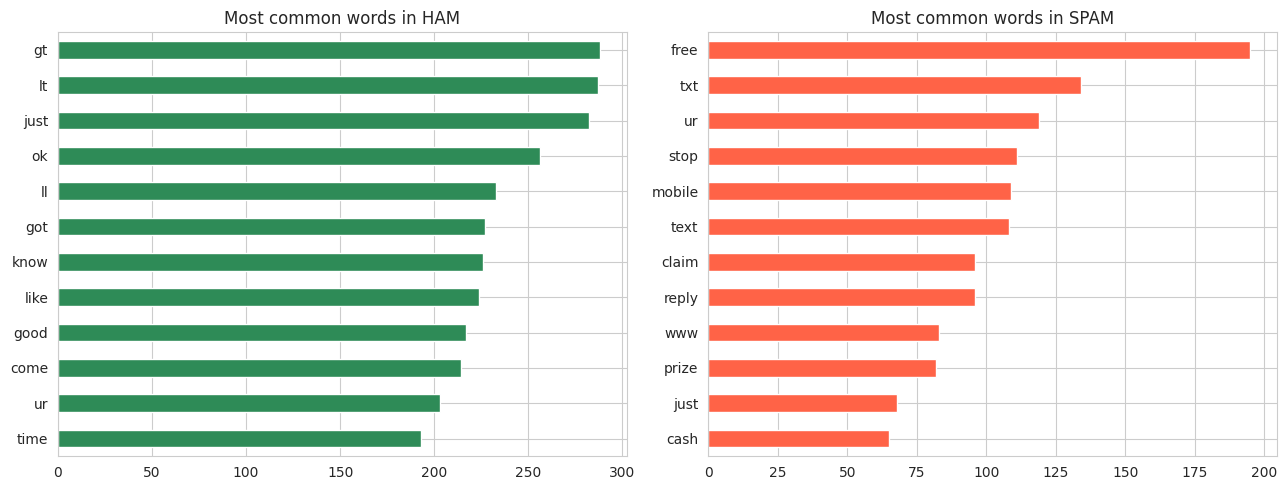

In [6]:
def top_words(texts, n=12):
    vec = CountVectorizer(stop_words="english")
    matrix = vec.fit_transform(texts)
    totals = np.asarray(matrix.sum(axis=0)).ravel()
    words = vec.get_feature_names_out()
    return pd.Series(totals, index=words).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_words(df.loc[df["label"] == "ham", "message"]).sort_values().plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Most common words in HAM")
top_words(df.loc[df["label"] == "spam", "message"]).sort_values().plot(kind="barh", ax=axes[1], color="tomato")
axes[1].set_title("Most common words in SPAM")
plt.tight_layout()
plt.show()

**Insight:** Spam uses words that push the reader to act or to pay, such as "free", "txt", "stop", "mobile", "claim", "reply", and "prize". Normal messages use everyday chat words. The words "gt" and "lt" in the ham list are leftovers of encoded symbols (like &lt; and &gt;) in the raw file, not real words. This difference in vocabulary is what Naive Bayes learns.

## 4. Train/Test Split

`stratify=y` keeps the same share of spam in both sets.

In [7]:
X = df["message"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", len(X_train), "| Test:", len(X_test))
print("Spam share in train: %.3f | in test: %.3f" % (y_train.mean(), y_test.mean()))

Train: 4135 | Test: 1034
Spam share in train: 0.126 | in test: 0.127


## 5. How Naive Bayes Works on Text

**Step 1: Turn text into numbers.** A model cannot read words, so `CountVectorizer` builds a vocabulary and counts how many times each word appears in each message. A tiny example:

In [8]:
demo = ["Free prize now", "Call me now", "Free free call"]
cv_demo = CountVectorizer()
matrix = cv_demo.fit_transform(demo)
pd.DataFrame(matrix.toarray(), columns=cv_demo.get_feature_names_out(), index=demo)

,call,free,me,now,prize
Free prize now,0,1,0,1,1
Call me now,1,0,1,1,0
Free free call,1,2,0,0,0


**Step 2: Learn how common each word is in each class.** For every word, Naive Bayes estimates how often it appears in spam messages and how often in ham messages.

**Step 3: Combine the evidence.** For a new message, it starts from the overall share of spam, then multiplies in the evidence from every word. It is called *naive* because it treats every word as independent of the others, which is not true in real language, but the model still works well in practice.

**Smoothing (`alpha`):** If a word was never seen in spam during training, its probability would be zero and would wipe out everything else. `alpha` adds a small count to every word to avoid that. A small `alpha` trusts the training data more, and a large `alpha` smooths more.

## 6. Train and Compare Models

All models are built as pipelines that turn the text into numbers and then classify it.

Since spam is the minority class, the models are compared with the **F1 score for spam** (a balance of precision and recall), using 5-fold cross-validation on the training set. A baseline that always predicts "ham" is included to show how much the models really learn.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Baseline (always ham)": make_pipeline(CountVectorizer(), DummyClassifier(strategy="most_frequent")),
    "Naive Bayes (alpha=0.1)": make_pipeline(CountVectorizer(), MultinomialNB(alpha=0.1)),
    "Naive Bayes (alpha=0.5)": make_pipeline(CountVectorizer(), MultinomialNB(alpha=0.5)),
    "Naive Bayes (alpha=1.0)": make_pipeline(CountVectorizer(), MultinomialNB(alpha=1.0)),
    "Naive Bayes (alpha=2.0)": make_pipeline(CountVectorizer(), MultinomialNB(alpha=2.0)),
    "Naive Bayes + TF-IDF": make_pipeline(TfidfVectorizer(), MultinomialNB(alpha=0.1)),
    "Logistic Regression + TF-IDF": make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)),
}

fitted = {}
rows = []
for name, model in candidates.items():
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "CV F1 (spam)": cv_f1.mean(),
        "Test accuracy": accuracy_score(y_test, pred),
        "Test precision": precision_score(y_test, pred, zero_division=0),
        "Test recall": recall_score(y_test, pred, zero_division=0),
        "Test F1": f1_score(y_test, pred, zero_division=0),
    })

results = pd.DataFrame(rows)
results.round(3)

,Model,CV F1 (spam),Test accuracy,Test precision,Test recall,Test F1
0,Baseline (always ham),0.000,0.873,0.000,0.000,0.000
1,Naive Bayes (alpha=0.1),0.943,0.982,0.924,0.931,0.928
2,Naive Bayes (alpha=0.5),0.943,0.986,0.947,0.947,0.947
3,Naive Bayes (alpha=1.0),0.934,0.982,0.959,0.893,0.925
4,Naive Bayes (alpha=2.0),0.917,0.980,0.966,0.870,0.916
5,Naive Bayes + TF-IDF,0.928,0.983,0.975,0.885,0.928
6,Logistic Regression + TF-IDF,0.845,0.964,0.961,0.748,0.841


**How to read this:**
- **Precision** (spam): of the messages flagged as spam, how many really are spam. Low precision means normal messages get blocked.
- **Recall** (spam): of all real spam, how many are caught. Low recall means spam gets through.
- **Baseline:** it reaches 87.3% accuracy but a recall of 0, because it never catches any spam. This shows why accuracy alone is misleading.

**Result:** Naive Bayes clearly beat the baseline. Alpha values of 0.1 and 0.5 had the same cross-validated F1 (0.943), and alpha 0.5 was chosen. A larger alpha raised precision but lowered recall (at alpha 2.0, precision 0.966 and recall 0.870). Naive Bayes with TF-IDF caught fewer spam messages (recall 0.885), and Logistic Regression with TF-IDF did worst (recall 0.748, F1 0.841). The simple count-based Naive Bayes was the best choice here.

## 7. Pick the Best Naive Bayes Model

The website will use the **count-based Naive Bayes**, because its prediction is simple arithmetic (add up a score for each word) that can be repeated in JavaScript. So the best model is chosen among the count-based Naive Bayes variants, using the cross-validated F1.

In [10]:
nb_results = results[results["Model"].str.startswith("Naive Bayes (alpha")]
best_name = nb_results.loc[nb_results["CV F1 (spam)"].idxmax(), "Model"]
best_model = fitted[best_name]
best_alpha = best_model.named_steps["multinomialnb"].alpha
print("Best model:", best_name)

pred = best_model.predict(X_test)
proba = best_model.predict_proba(X_test)[:, 1]

final = {
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "f1": f1_score(y_test, pred),
}
for name, value in final.items():
    print(f"{name:10s} {value:.3f}")
print()
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

Best model: Naive Bayes (alpha=0.5)
accuracy   0.986
precision  0.947
recall     0.947
f1         0.947

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.95      0.95      0.95       131

    accuracy                           0.99      1034
   macro avg       0.97      0.97      0.97      1034
weighted avg       0.99      0.99      0.99      1034



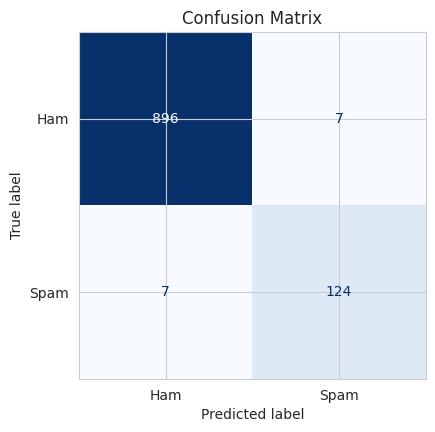

In [11]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test,
    display_labels=["Ham", "Spam"], cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Confusion Matrix")
plt.show()

**How to read this:** The top-right cell holds **ham messages wrongly flagged as spam** (false positives), and the bottom-left cell holds **spam that got through** (false negatives). For a spam filter, a false positive is usually worse, because an important message may be lost, so precision matters a lot.

**Result:** Out of 1,034 test messages (903 ham and 131 spam), the model wrongly flagged 7 normal messages as spam and missed 7 spam messages.

## 8. Changing the Decision Threshold

The model outputs a probability of spam, and 0.5 is only the default cut-off. A higher threshold flags a message only when the model is very sure, which gives fewer false alarms (higher precision) but lets more spam through (lower recall).

In [12]:
rows = []
for t in [0.5, 0.7, 0.9, 0.99]:
    pred_t = (proba >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t, zero_division=0),
        "Ham wrongly flagged": int(((pred_t == 1) & (y_test == 0)).sum()),
        "Spam missed": int(((pred_t == 0) & (y_test == 1)).sum()),
    })
pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,Ham wrongly flagged,Spam missed
0,0.50,0.947,0.947,7,7
1,0.70,0.975,0.901,3,13
2,0.90,0.975,0.893,3,14
3,0.99,1.000,0.863,0,18


**Result:** Raising the threshold trades recall for precision. At the default 0.5, the model made 7 false alarms and missed 7 spam messages. At 0.99, there were no false alarms at all (precision 1.000), but 18 spam messages got through (recall 0.863). A phone company that never wants to block a real message could choose a high threshold, while a company that wants to catch as much spam as possible would keep it lower.

## 9. Where Does the Model Make Mistakes?

In [13]:
pd.set_option("display.max_colwidth", 140)

test_df = pd.DataFrame({"message": X_test.values, "actual": y_test.values, "predicted": pred,
                        "spam_probability": proba.round(3)})

print("Ham wrongly flagged as spam (false positives):")
display(test_df[(test_df["actual"] == 0) & (test_df["predicted"] == 1)].head(5))

print("Spam that got through (false negatives):")
display(test_df[(test_df["actual"] == 1) & (test_df["predicted"] == 0)].head(5))

Ham wrongly flagged as spam (false positives):


,message,actual,predicted,spam_probability
29,Your daily text from me – a favour this time,0,1,0.551
293,Are you free now?can i call now?,0,1,0.627
327,K k:) sms chat with me.,0,1,0.616
494,"Received, understood n acted upon!",0,1,0.608
689,Unlimited texts. Limited minutes.,0,1,0.921


Spam that got through (false negatives):


,message,actual,predicted,spam_probability
308,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 09099726395 Lucy x Calls£1/min...,1,0,0.000
326,Missed call alert. These numbers called but left no message. 07008009200,1,0,0.004
437,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...,1,0,0.000
486,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ...",1,0,0.000
544,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. ...",1,0,0.009


**What the mistakes show:**
- **False alarms** are short, everyday messages that contain words common in spam, such as "text", "free", "call", and "sms" (for example, "Are you free now? can i call now?"). The model gave them spam probabilities of about 55% to 92%, so they were close calls.
- **Missed spam** is often spam that avoids typical spam words: adult-content messages, a quiz competition, a "missed call" alert with a phone number, and an event promotion. The model gave these almost 0% spam probability, so it was confidently wrong.

## 10. Which Words Matter Most?

For every word, the model learned how much more likely it is to appear in spam than in ham. A positive number means "spam word", and a negative number means "normal word". To avoid noise, only words that appear a reasonable number of times are shown.

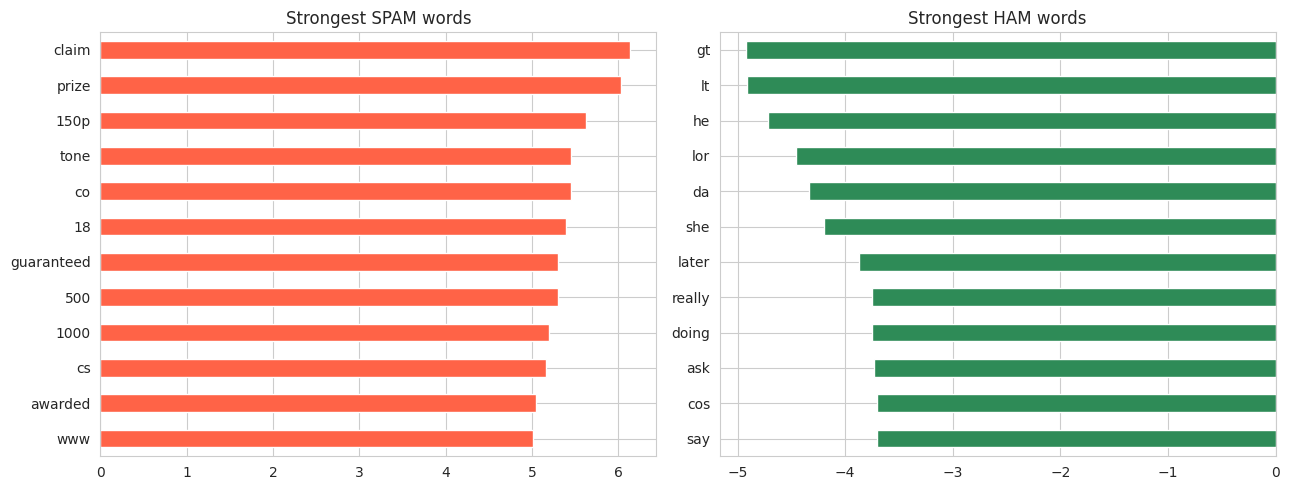

In [14]:
vectorizer = best_model.named_steps["countvectorizer"]
nb = best_model.named_steps["multinomialnb"]

words = vectorizer.get_feature_names_out()
log_odds = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
word_table = pd.DataFrame({
    "word": words,
    "log_odds": log_odds,
    "spam_count": nb.feature_count_[1],
    "ham_count": nb.feature_count_[0],
})

spam_words = word_table[word_table["spam_count"] >= 10].sort_values("log_odds", ascending=False).head(12)
ham_words = word_table[word_table["ham_count"] >= 30].sort_values("log_odds").head(12)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
spam_words.sort_values("log_odds").plot(x="word", y="log_odds", kind="barh", ax=axes[0], color="tomato", legend=False)
axes[0].set_title("Strongest SPAM words")
axes[0].set_ylabel("")
ham_words.sort_values("log_odds", ascending=False).plot(x="word", y="log_odds", kind="barh", ax=axes[1], color="seagreen", legend=False)
axes[1].set_title("Strongest HAM words")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Insight:** The strongest spam words are "claim", "prize", "guaranteed", "awarded", and "www", plus prices and numbers such as "150p", "500", and "1000". Money and rewards are the clearest sign of spam. The strongest ham words are casual chat words such as "he", "she", "later", "really", and "doing", and informal words such as "lor", "da", and "cos". The words "gt" and "lt" come from encoded symbols in the file.

## 11. Try Your Own Messages

In [15]:
def check_message(text):
    prob = best_model.predict_proba([text])[0, 1]
    label = "SPAM" if prob >= 0.5 else "HAM"
    print(f"{label:5s} ({prob * 100:5.1f}% spam)  <-  {text}")

check_message("WINNER!! You have been selected to receive a 900 pound prize reward. Call 09061701461 now to claim.")
check_message("Ok, I will call you after the meeting. Can you send me the address?")
check_message("Free entry in our weekly competition! Text WIN to 80086 to claim your prize.")
check_message("Are we still meeting for lunch tomorrow?")

SPAM  (100.0% spam)  <-  WINNER!! You have been selected to receive a 900 pound prize reward. Call 09061701461 now to claim.
HAM   (  0.0% spam)  <-  Ok, I will call you after the meeting. Can you send me the address?
SPAM  (100.0% spam)  <-  Free entry in our weekly competition! Text WIN to 80086 to claim your prize.
HAM   (  0.0% spam)  <-  Are we still meeting for lunch tomorrow?


## 12. Export the Model for the Website

A Naive Bayes prediction is simple arithmetic: for every word in the message, add the word's score (how much it points to spam), start from the overall spam tendency, and turn the total into a probability. So only two things need to be saved: **one score per word** and **one starting value**. The web page repeats the same steps in JavaScript.

In [16]:
model_json = {
    "prior": float(nb.class_log_prior_[1] - nb.class_log_prior_[0]),
    "words": {w: round(float(s), 4) for w, s in zip(words, log_odds)},
    "test_accuracy": round(final["accuracy"] * 100, 1),
    "test_precision": round(final["precision"] * 100, 1),
    "test_recall": round(final["recall"] * 100, 1),
}

with open("model.json", "w", encoding="utf-8") as f:
    json.dump(model_json, f, separators=(",", ":"), ensure_ascii=False)

print("Words in vocabulary:", len(words))
print("model.json size: %.0f KB" % (os.path.getsize("model.json") / 1e3))

# Values for checking the website
spam_text = "WINNER!! You have been selected to receive a 900 pound prize reward. Call 09061701461 now to claim."
ham_text = "Ok, I will call you after the meeting. Can you send me the address?"
print("\nType this message into the website:")
print(spam_text)
print("Notebook spam probability: %.1f%%" % (best_model.predict_proba([spam_text])[0, 1] * 100))
print("\nThen this one:")
print(ham_text)
print("Notebook spam probability: %.1f%%" % (best_model.predict_proba([ham_text])[0, 1] * 100))

try:
    from google.colab import files
    files.download("model.json")
except ImportError:
    pass

Words in vocabulary: 7680
model.json size: 126 KB

Type this message into the website:
WINNER!! You have been selected to receive a 900 pound prize reward. Call 09061701461 now to claim.
Notebook spam probability: 100.0%

Then this one:
Ok, I will call you after the meeting. Can you send me the address?
Notebook spam probability: 0.0%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Results Summary

In [17]:
best_row = results[results["Model"] == best_name].iloc[0]
print(f"Best model:               {best_name}")
print(f"Baseline accuracy:        {results.loc[0, 'Test accuracy']:.3f} (recall {results.loc[0, 'Test recall']:.2f})")
print(f"Accuracy:                 {final['accuracy']:.3f}")
print(f"Spam precision / recall:  {final['precision']:.3f} / {final['recall']:.3f}")
print(f"Spam F1:                  {final['f1']:.3f}")
print("Strongest spam word:     ", spam_words.iloc[0]["word"])

Best model:               Naive Bayes (alpha=0.5)
Baseline accuracy:        0.873 (recall 0.00)
Accuracy:                 0.986
Spam precision / recall:  0.947 / 0.947
Spam F1:                  0.947
Strongest spam word:      claim


## 14. Conclusion, Limitations, and Next Steps

**Conclusion:** Naive Bayes with alpha 0.5 detected spam with an accuracy of 98.6%, a spam precision of 94.7%, and a spam recall of 94.7% on 1,034 unseen messages. A baseline that always predicts "ham" reaches 87.3% accuracy but catches no spam at all, so accuracy alone would be misleading on this data. The simple count-based Naive Bayes beat both Naive Bayes with TF-IDF and Logistic Regression in cross-validated F1. The model is weakest on spam that avoids typical spam words, and a higher decision threshold can remove false alarms at the cost of missing more spam.

**Limitations**
- The messages are English texts collected years ago (mainly from the UK and Singapore), so the model may miss modern spam and messages in other languages or mixed languages such as Hinglish.
- The model only looks at which words appear, not their order or meaning, and it treats every word as independent.
- Spammers can change their wording to avoid typical spam words.
- The file contains leftover encoded symbols ("gt", "lt") that were not cleaned.
- The test set is small, so a few messages can move the scores noticeably.

**Next steps**
- Clean the encoded symbols and add features such as message length, the number of digits, and the presence of links or phone numbers
- Try n-grams (word pairs) in the vectorizer
- Compare with Support Vector Machines or a small neural network
- Train on a more recent or India-specific spam dataset